# Лабораторно-практичне заняття №5. Частина 1
## Придушення шумів у координатних даних: ковзні фільтри і спектр похибки

**Перед початком роботи:** меню **File → Save a copy in Drive** — працюйте у своїй копії.
Потім у Блоці 1 вкажіть свій `STUDENT_NUMBER` і запустіть усе кнопкою **▶ Run all**.

Ваше завдання — дописати класи фільтрів у Блоці 3. Решта блоків готові: не змінюйте їх.

In [1]:
# --- Блок 1. Налаштування ---
import numpy as np
import matplotlib.pyplot as plt
from collections import deque   # знадобиться для медіанного фільтра

STUDENT_NUMBER = 14     # ваш номер у списку групи: від нього залежать шум і викиди

FS = 10.0               # частота вимірювань, Гц (як у GPS-приймача на 10 Гц)
DURATION = 120.0        # тривалість запису, с
NOISE_STD = 3.0         # СКВ (стандартне відхилення σ) шуму координати, м
OUTLIER_SHARE = 0.02    # частка вимірювань-викидів (стрибків на 20–40 м)

In [2]:
# --- Блок 2. Генератор даних: справжній трек і «виміряний» ---
T = np.arange(0, DURATION, 1 / FS)


def true_track(t):
    """Справжній трек, м: прямий проїзд, поворот на 90°, «змійка» з об'їздами, знову прямо."""
    x, y = np.zeros_like(t), np.zeros_like(t)
    v = 10.0                                         # м/с
    for i, ti in enumerate(t):
        if ti < 30:                                  # прямо на схід
            x[i], y[i] = v * ti, 0.0
        elif ti < 45:                                # поворот ліворуч по дузі радіусом 95 м
            a = (ti - 30) / 15 * np.pi / 2
            x[i], y[i] = 300 + 95 * np.sin(a), 95 * (1 - np.cos(a))
        elif ti < 90:                                # на північ «змійкою»: три об'їзди ліворуч до 50 м, період 15 с
            s = ti - 45
            x[i], y[i] = 395 - 25 * (1 - np.cos(2 * np.pi * s / 15)), 95 + v * s
        else:                                        # прямо на північ
            x[i], y[i] = 395, 545 + v * (ti - 90)
    return x, y


X_TRUE, Y_TRUE = true_track(T)
rng = np.random.default_rng(STUDENT_NUMBER)
X_MEAS = X_TRUE + rng.normal(0, NOISE_STD, T.size)
Y_MEAS = Y_TRUE + rng.normal(0, NOISE_STD, T.size)
OUTLIERS = rng.random(T.size) < OUTLIER_SHARE          # де стоять викиди
OUTLIERS[0] = False                                    # перше вимірювання без викиду: з нього стартують фільтри
angle = rng.uniform(0, 2 * np.pi, T.size)
jump = rng.uniform(20, 40, T.size)
X_MEAS[OUTLIERS] += (jump * np.cos(angle))[OUTLIERS]
Y_MEAS[OUTLIERS] += (jump * np.sin(angle))[OUTLIERS]
print(f'Студент №{STUDENT_NUMBER}: {T.size} вимірювань по {1 / FS:.1f} с, викидів {OUTLIERS.sum()}')

Студент №14: 1200 вимірювань по 0.1 с, викидів 22


In [3]:
# --- Блок 3. Ваш код: потокові фільтри ---

class SMA:
    """Ковзне середнє останніх W вимірювань."""

    def __init__(self, window):
        self.window = window
        self.buffer = [0] * window
        self.index = 0
        self.count = 0
        self.total = 0.0

    def update(self, x):
        if self.count == self.window:
            self.total -= self.buffer[self.index]
        else:
            self.count += 1

        self.buffer[self.index] = x
        self.total += x
        self.index = (self.index + 1) % self.window

        return self.total / self.count


class EMA:
    """Експоненційне ковзне середнє."""

    def __init__(self, alpha):
        self.alpha = alpha
        self.previous = None

    def update(self, x):
        if self.previous is None:
            self.previous = x
        else:
            self.previous = (
                self.alpha * x
                + (1 - self.alpha) * self.previous
            )

        return self.previous


class Median:
    """Медіана останніх W вимірювань."""

    def __init__(self, window):
        self.window = window
        self.values = deque(maxlen=window)

    def update(self, x):
        self.values.append(x)
        return float(np.median(self.values))


In [4]:
# --- Блок 4. Перевірка вашого коду (не змінюйте) ---

import time


def check_filters():
    test = np.random.default_rng(7).normal(0, 1, 200).cumsum()
    expected = {
        'SMA': [test[max(0, i - 9):i + 1].mean() for i in range(test.size)],
        'Median': [np.median(test[max(0, i - 8):i + 1]) for i in range(test.size)],
    }
    ema, y = [], None
    for v in test:
        y = v if y is None else 0.3 * v + 0.7 * y
        ema.append(y)
    expected['EMA'] = ema
    passed = []
    for name, make in (('SMA', lambda: SMA(10)), ('EMA', lambda: EMA(0.3)), ('Median', lambda: Median(9))):
        if name not in globals():
            print(f'{name}: класу ще немає — вставте свої фільтри з частини 1 у Блок 3 і запустіть цю комірку ще раз.')
            continue
        try:
            f = make()
            got = [f.update(v) for v in test]
        except NotImplementedError as e:
            print(f'{name}: {e}, а потім запустіть цю комірку ще раз.')
            continue
        except Exception as e:
            print(f'{name}: помилка під час роботи фільтра — {type(e).__name__}: {e}')
            continue
        if any(g is None for g in got):
            print(f'{name}: метод update нічого не повертає — додайте return.')
            continue
        bad = np.flatnonzero(np.abs(np.array(got, dtype=float) - np.array(expected[name])) > 1e-9)
        if bad.size == 0:
            print(f'{name}: перевірка пройдена.')
            passed.append(name)
            continue
        hint = (' Підказка: коли значень парна кількість, медіана — середнє двох центральних (так рахує np.median).'
                if name == 'Median' and bad[0] < 8 and bad[0] % 2 == 1 else '')
        print(f'{name}: розбіжність з очікуваним уже на вимірюванні №{bad[0]} '
              f'(отримано {got[bad[0]]:.4f}, очікувано {expected[name][bad[0]]:.4f}).{hint}')
    if 'SMA' in passed:                      # O(1): час обробки не має залежати від розміру вікна
        def sma_time(w, n=20000):
            f, t0 = SMA(w), time.perf_counter()
            for v in range(n):
                f.update(float(v))
            return time.perf_counter() - t0
        ratio = sma_time(10_000) / sma_time(10)
        print('SMA: час обробки не залежить від W — схоже на O(1).' if ratio < 3 else
              f'SMA: з вікном 10 000 обробка в {ratio:.0f} разів повільніша, ніж з вікном 10, — '
              'схоже, ви щоразу підсумовуєте все вікно.')

check_filters()

SMA: перевірка пройдена.
EMA: перевірка пройдена.
Median: перевірка пройдена.
SMA: час обробки не залежить від W — схоже на O(1).


In [5]:
# --- Блок 5. Запуск фільтрів, похибки, рисунки (не змінюйте) ---

def apply(make_filter):
    """Пропускає трек через фільтр, окремий для x і для y; повертає (x, y)."""
    fx, fy = make_filter(), make_filter()
    xs = np.array([fx.update(v) for v in X_MEAS])
    ys = np.array([fy.update(v) for v in Y_MEAS])
    return xs, ys


def rmse(xs, ys, skip=0.0):
    """Середньоквадратична похибка положення, м (перші skip секунд не враховуються)."""
    k = T >= skip
    return float(np.sqrt(np.mean((xs[k] - X_TRUE[k]) ** 2 + (ys[k] - Y_TRUE[k]) ** 2)))


def error_spectrum(xs):
    """Амплітудний спектр похибки координати x (без середнього), м."""
    e = xs - X_TRUE
    e = e - e.mean()
    return np.fft.rfftfreq(e.size, 1 / FS), 2 * np.abs(np.fft.rfft(e)) / e.size


def max_error(xs, ys, skip=5.0):
    """Найбільша похибка положення, м, і момент, коли вона сталася, с (перші skip секунд не враховуються)."""
    k = T >= skip
    err = np.hypot(xs - X_TRUE, ys - Y_TRUE)[k]
    i = int(np.argmax(err))
    return float(err[i]), float(T[k][i])


def compare(results, title=''):
    """results — словник {назва: (x, y)}; друкує похибки і будує поворот і «змійку» крупно, похибку в часі та її спектр."""
    results = {'Виміряно': (X_MEAS, Y_MEAS), **results}
    for name, (xs, ys) in results.items():
        print(f'{name:>26}: RMSE {rmse(xs, ys, skip=5):6.2f} м')
    fig, ((ax0, ax1), (ax2, ax3)) = plt.subplots(2, 2, figsize=(14, 10), gridspec_kw={'width_ratios': [1.6, 1]})
    fig.suptitle(f'Студент №{STUDENT_NUMBER}. {title}', fontsize=13)
    for ax, (x0, x1, y0, y1), name in ((ax0, (240, 430, -25, 130), 'Поворот крупно'),
                                       (ax1, (320, 430, 60, 560), '«Змійка» крупно')):
        ax.plot(X_TRUE, Y_TRUE, 'k--', lw=1.5, label='Справжній трек')
        for label, (xs, ys) in results.items():
            style = dict(color='lightgray', lw=0.8) if label == 'Виміряно' else dict(lw=1.5)
            ax.plot(xs, ys, label=label, **style)
        ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
        ax.set_title(name); ax.set_xlabel('x, м'); ax.set_ylabel('y, м')
    ax0.set_aspect('equal'); ax0.legend(fontsize=9, loc='upper left')
    for name, (xs, ys) in results.items():
        err = np.hypot(xs - X_TRUE, ys - Y_TRUE)
        style = dict(color='lightgray', lw=0.8) if name == 'Виміряно' else dict(lw=1.2)
        ax2.plot(T, err, label=name, **style)
        f, a = error_spectrum(xs)
        ax3.loglog(f[1:], a[1:], label=name, **style)
    ax2.set_title('Похибка положення в часі (поворот і «змійку» підсвічено)')
    ax2.set_xlabel('t, с'); ax2.set_ylabel('м'); ax2.set_ylim(0, 40)
    for t0, t1 in ((30, 45), (45, 90)):
        ax2.axvspan(t0, t1, color='orange' if t0 == 30 else 'yellow', alpha=0.15)
    ax3.set_title('Спектр похибки координати x'); ax3.set_xlabel('частота, Гц'); ax3.set_ylabel('амплітуда, м')
    ax3.axvline(1 / 15, color='gray', ls=':')
    ax3.text(1 / 15, 0.97, ' частота «змійки»', fontsize=9, va='top', transform=ax3.get_xaxis_transform())
    ax2.legend(fontsize=9, loc='upper right'); ax3.legend(fontsize=9, loc='lower left')
    for ax in (ax2, ax3):
        ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

                  Виміряно: RMSE   6.02 м
                   SMA W=5: RMSE   3.45 м
                EMA α=0.33: RMSE   3.44 м
               Медіана W=5: RMSE   3.17 м


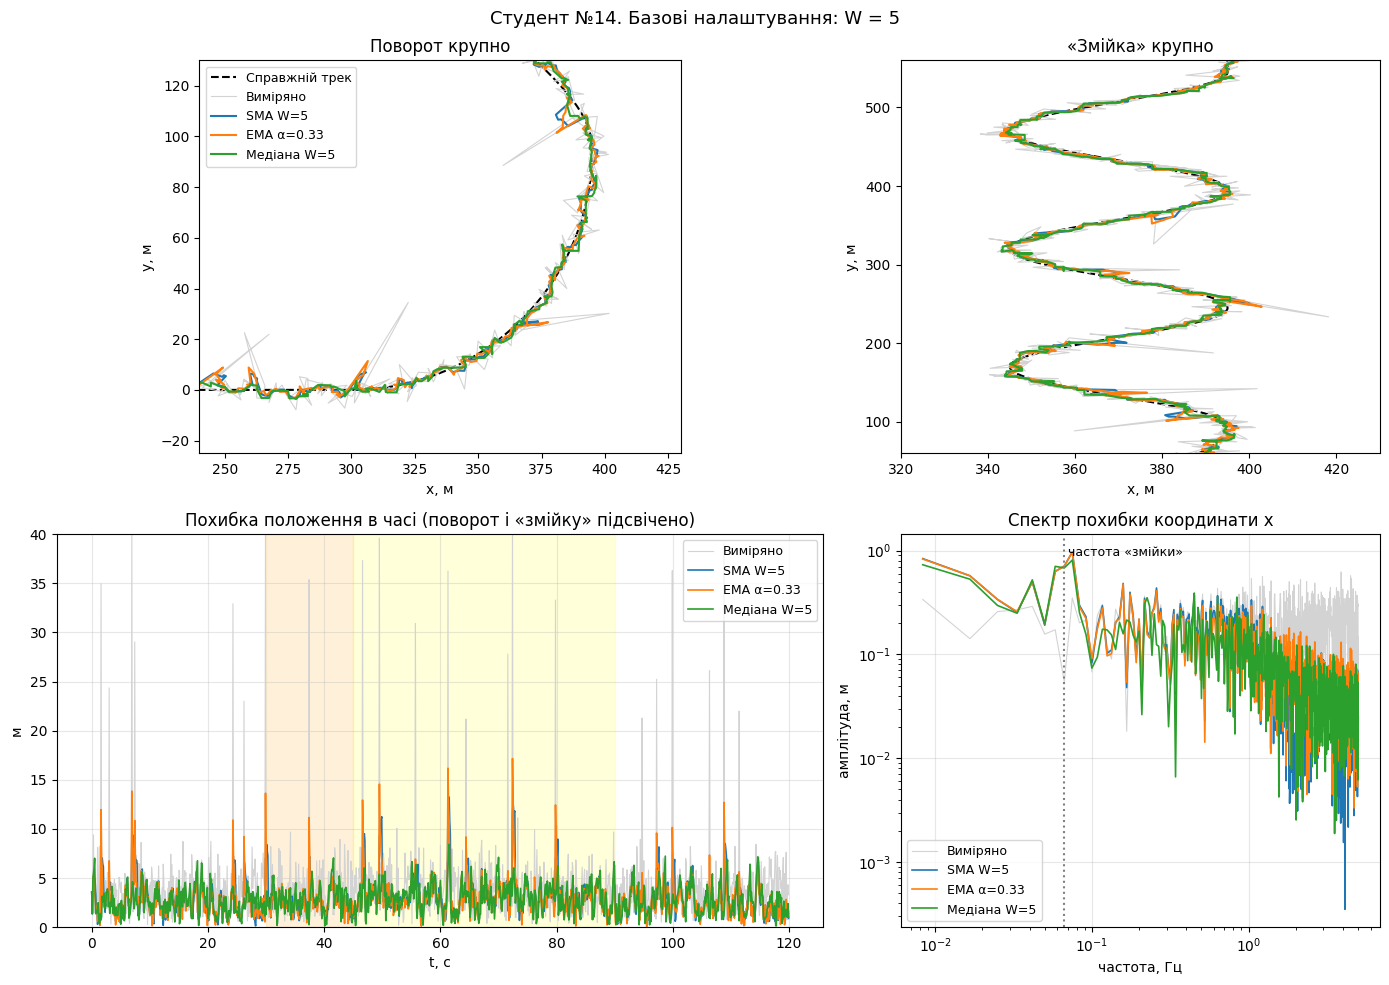

In [6]:
compare({
    'SMA W=5': apply(lambda: SMA(5)),
    'EMA α=0.33': apply(lambda: EMA(2 / (5 + 1))),
    'Медіана W=5': apply(lambda: Median(5))
}, 'Базові налаштування: W = 5')

                  Виміряно: RMSE   6.02 м
                  SMA W=50: RMSE  26.38 м
                EMA α=0.04: RMSE  25.50 м


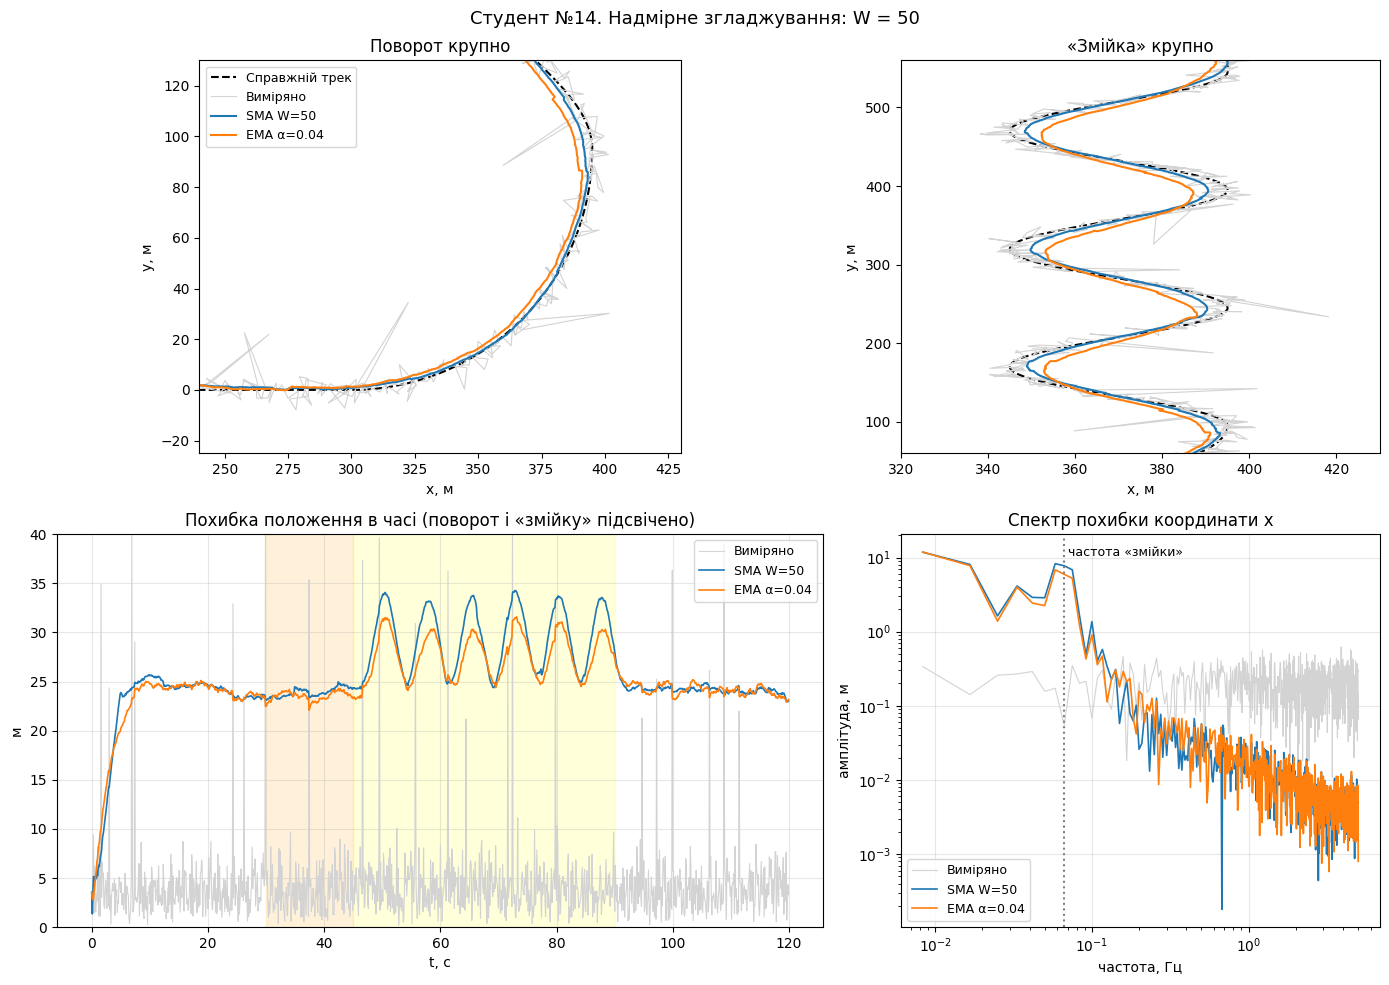

In [7]:
compare({
    'SMA W=50': apply(lambda: SMA(50)),
    'EMA α=0.04': apply(lambda: EMA(2 / (50 + 1)))
}, 'Надмірне згладжування: W = 50')

                  Виміряно: RMSE   6.02 м
                   SMA W=5: RMSE   3.45 м
               Медіана W=5: RMSE   3.17 м


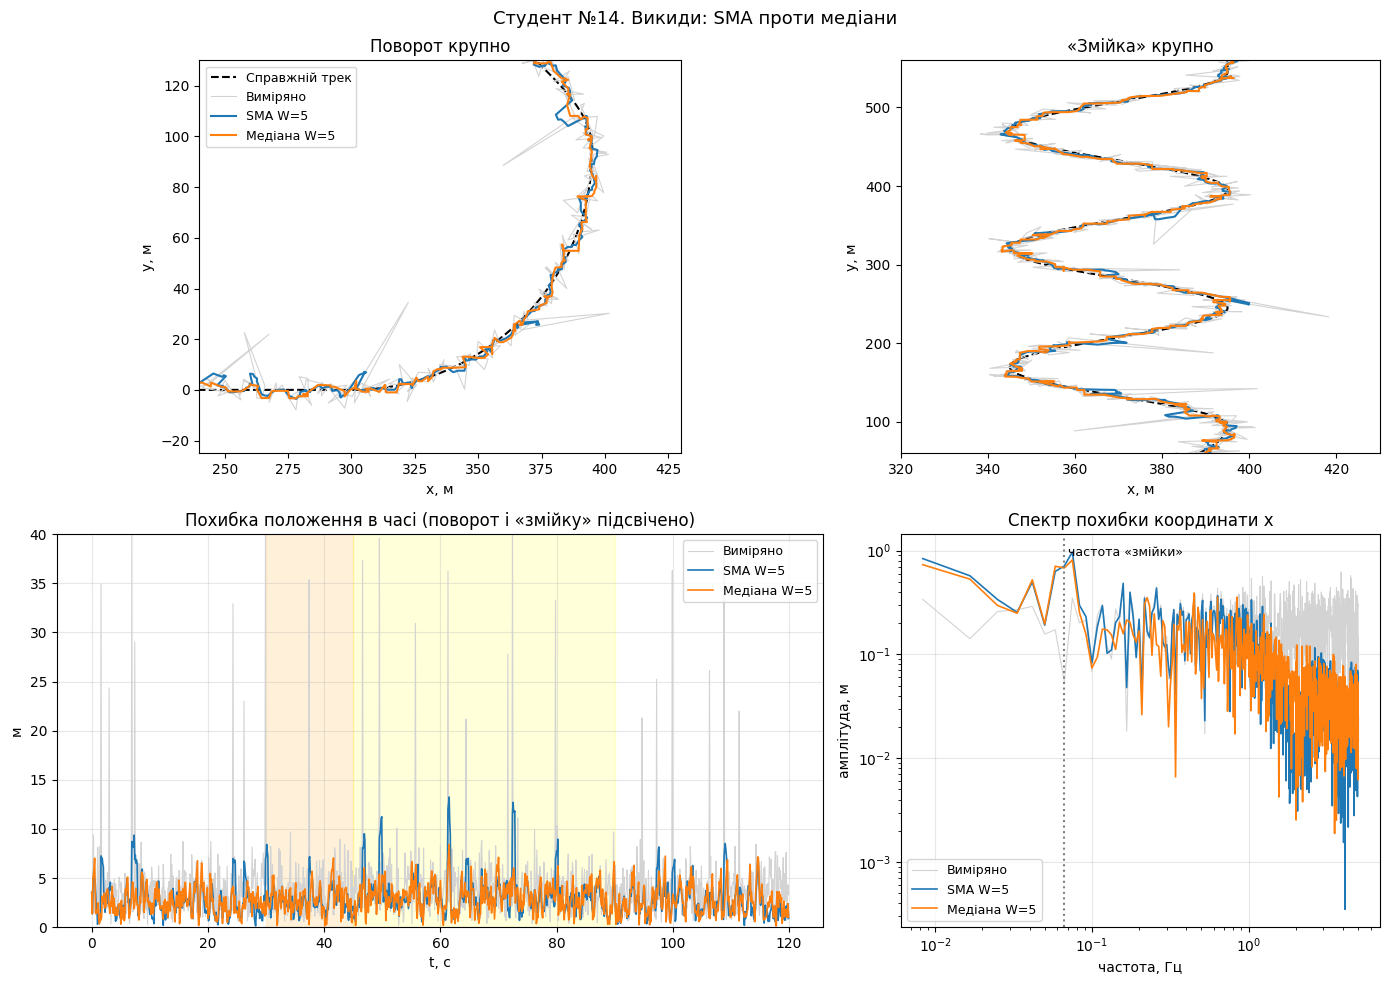

    Виміряно: найбільша похибка  42.9 м на 72.4 с
     SMA W=5: найбільша похибка  13.2 м на 61.5 с
 Медіана W=5: найбільша похибка   8.4 м на 61.5 с


In [8]:
results = {
    'SMA W=5': apply(lambda: SMA(5)),
    'Медіана W=5': apply(lambda: Median(5))
}

compare(results, 'Викиди: SMA проти медіани')

for name, (xs, ys) in {
    'Виміряно': (X_MEAS, Y_MEAS),
    **results
}.items():
    e, t = max_error(xs, ys)
    print(
        f'{name:>12}: найбільша похибка '
        f'{e:5.1f} м на {t:.1f} с'
    )

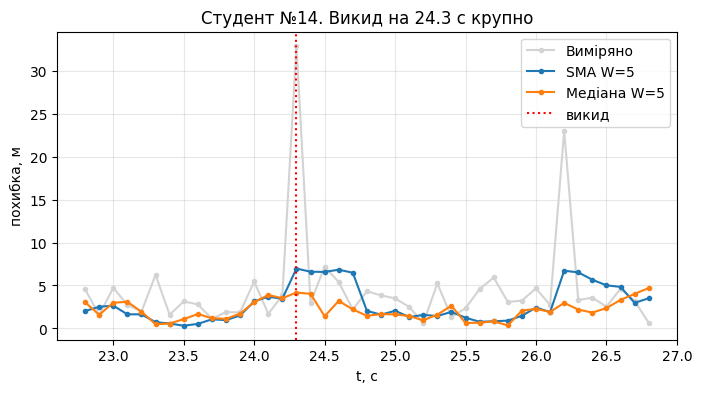

In [9]:
k = np.flatnonzero(OUTLIERS & (T >= 10))[0]
near = (T >= T[k] - 1.5) & (T <= T[k] + 2.5)

plt.figure(figsize=(8, 4))

for name, (xs, ys) in {
    'Виміряно': (X_MEAS, Y_MEAS),
    **results
}.items():
    err = np.hypot(xs - X_TRUE, ys - Y_TRUE)
    style = dict(color='lightgray') if name == 'Виміряно' else {}

    plt.plot(
        T[near], err[near],
        marker='o', ms=3,
        label=name, **style
    )

plt.axvline(T[k], color='red', ls=':', label='викид')
plt.xlabel('t, с')
plt.ylabel('похибка, м')
plt.grid(alpha=0.3)
plt.legend()
plt.title(
    f'Студент №{STUDENT_NUMBER}. '
    f'Викид на {T[k]:.1f} с крупно'
)
plt.show()


In [10]:
for burst in (1, 2, 3):
    m = Median(5)

    out = [
        m.update(v)
        for v in [0] * 5 + [30] * burst + [0] * 5
    ]

    print(
        f'{burst} викид(и) поспіль по 30 м → '
        f'найбільше значення на виході медіани W=5: '
        f'{max(out):.0f} м'
    )

1 викид(и) поспіль по 30 м → найбільше значення на виході медіани W=5: 0 м
2 викид(и) поспіль по 30 м → найбільше значення на виході медіани W=5: 0 м
3 викид(и) поспіль по 30 м → найбільше значення на виході медіани W=5: 30 м


SMA: найкраще W = 4, RMSE 3.43 м
EMA: найкраще W = 4, RMSE 3.41 м
Медіана: найкраще W = 3, RMSE 3.06 м


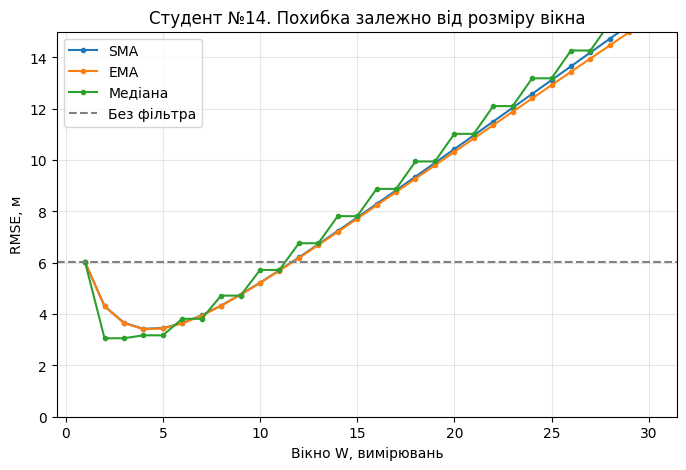

In [11]:
windows = range(1, 31)

curves = {
    'SMA': [
        rmse(*apply(lambda: SMA(w)), skip=5)
        for w in windows
    ],
    'EMA': [
        rmse(*apply(lambda: EMA(2 / (w + 1))), skip=5)
        for w in windows
    ],
    'Медіана': [
        rmse(*apply(lambda: Median(w | 1)), skip=5)
        for w in windows
    ]
}

plt.figure(figsize=(8, 5))

for name, c in curves.items():
    plt.plot(windows, c, marker='o', ms=3, label=name)

    w_best = list(windows)[int(np.argmin(c))]

    if name == 'Медіана':
        w_best |= 1

    print(
        f'{name}: найкраще W = {w_best}, '
        f'RMSE {min(c):.2f} м'
    )

plt.axhline(
    rmse(X_MEAS, Y_MEAS, skip=5),
    color='gray',
    ls='--',
    label='Без фільтра'
)

plt.xlabel('Вікно W, вимірювань')
plt.ylabel('RMSE, м')
plt.ylim(0, 15)
plt.grid(alpha=0.3)
plt.legend()
plt.title(
    f'Студент №{STUDENT_NUMBER}. '
    'Похибка залежно від розміру вікна'
)

plt.show()

In [ ]:
# --- Блок 6. Інтерактивне порівняння (запустіть після того, як фільтри пройдуть перевірку) ---
from ipywidgets import interact, IntSlider


@interact(window=IntSlider(value=5, min=1, max=60, description='W', continuous_update=False))
def explore(window):
    try:
        SMA(1).update(0.0), EMA(0.5).update(0.0), Median(1).update(0.0)
    except NotImplementedError:
        print('Спершу допишіть фільтри в Блоці 3 — тоді тут з\'являться рисунки.')
        return
    compare({f'SMA W={window}': apply(lambda: SMA(window)),
             f'EMA α={2 / (window + 1):.3f}': apply(lambda: EMA(2 / (window + 1))),
             f'Медіана W={window | 1}': apply(lambda: Median(window | 1))},
            f'Вікно W = {window} вимірювань ({window / FS:.1f} с)')

interactive(children=(IntSlider(value=5, continuous_update=False, description='W', max=60, min=1), Output()), …

## Експерименти
Додавайте нижче по одній комірці на кожен пункт методички.